# Notebook 02 — Materials Feature Engineering & Model Selection

**Purpose:** Compare composition-only and composition-plus-structure features for four material-property targets.

**Validation policy:** Connected chemical systems and repeated `material_id` records are kept in the same group. A single grouped holdout is reserved for final testing. Candidate models are selected by 3-fold `GroupKFold` MAE on the training partition only.

**Important:** This CSV does not contain crystal structures, so this notebook does not train a crystal graph neural network. All reported metrics are experimental and should not be presented as production performance.

In [1]:
from pathlib import Path
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

RANDOM_STATE = 42
TARGETS = [
    'formation_energy_per_atom_eV', 'band_gap_eV',
    'bulk_modulus_GPa', 'shear_modulus_GPa'
]
DATA_FILENAME = 'DS1_material_properties_5500.csv'
OUTPUT_DIR = Path('..') / 'outputs' / 'notebook_02'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

candidates = []
if os.getenv('MATRISK_DATA_ROOT'):
    candidates.append(Path(os.environ['MATRISK_DATA_ROOT']))
# Common locations when launched from ML/notebooks, repository root, or ML.
for p in [Path('../../Data/raw'), Path('../../Data'), Path('../../../Data/raw'), Path('../../../Data'),
          Path('../Data/raw'), Path('../Data'), Path('../../data/raw'), Path('../../data'),
          Path('Data/raw'), Path('Data'), Path('/mnt/data')]:
    candidates.append(p)

data_path = next((p / DATA_FILENAME for p in candidates if (p / DATA_FILENAME).is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        f'Could not find {DATA_FILENAME}. Set MATRISK_DATA_ROOT to the folder containing the CSV. '
        f'Searched: {[str(p.resolve()) for p in candidates]}'
    )
df = pd.read_csv(data_path)
missing_cols = sorted(set(['material_id','formula','crystal_system','spacegroup_number'] + TARGETS) - set(df.columns))
if missing_cols:
    raise ValueError(f'Required columns missing: {missing_cols}')
print(f'Loaded: {data_path.resolve()}')
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Unique material IDs: {df.material_id.nunique():,}; unique formulas: {df.formula.nunique():,}')
display(df.head())

Loaded: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS1_material_properties_5500.csv
Shape: 5,500 rows × 18 columns
Unique material IDs: 5,479; unique formulas: 5,002


,material_id,formula,n_elements,crystal_system,spacegroup_number,category,formation_energy_per_atom_eV,energy_above_hull_eV,band_gap_eV,is_metal,bulk_modulus_GPa,shear_modulus_GPa,poisson_ratio,density_g_cm3,nsites,volume_A3,melting_point_K,is_stable
0,mp-121959,Ta3Au3H2,3,hexagonal,185,Chalcogenide,-0.6329,0.0175,1.940,0,26.87,13.47,0.2918,4.343,2,96.38,1142.0,1
1,mp-23248,Al3Rh4W3,3,hexagonal,171,Alloy,-1.2275,0.2124,0.000,1,50.30,33.94,0.2326,6.757,4,365.02,1244.0,0
2,mp-526982,Pd3Te3,2,cubic,227,Metal,0.1265,0.0993,0.000,1,256.03,125.93,0.2849,10.501,4,642.24,1178.0,0
3,mp-984775,Ne4Cd4,2,tetragonal,81,Nitride,-0.4655,0.0534,1.830,0,461.87,233.17,0.2888,1.754,32,820.52,1130.0,0
4,mp-965909,Al4Rh,2,cubic,202,Nitride,-0.6142,0.0501,1.264,0,187.79,148.00,0.1900,3.360,2,87.85,306.0,0


## 1. Formula parsing and composition features

The parser handles ordinary flat chemical formulae such as `Al2O3` and `Fe`. It intentionally rejects parentheses, charge notation, fractional stoichiometry, and other unsupported forms. Composition features are elemental atomic fractions; formula scaling does not affect fractions.

In [2]:
ELEMENT_RE = re.compile(r'([A-Z][a-z]?)([0-9]*(?:\.[0-9]+)?)')

def parse_formula(formula):
    if not isinstance(formula, str) or not formula or any(ch in formula for ch in '()[]{}+-·'):
        return None
    matches = list(ELEMENT_RE.finditer(formula))
    if not matches or ''.join(m.group(0) for m in matches) != formula:
        return None
    amounts = {}
    for m in matches:
        el, raw = m.groups()
        amount = float(raw) if raw else 1.0
        if not np.isfinite(amount) or amount <= 0:
            return None
        amounts[el] = amounts.get(el, 0.0) + amount
    total = sum(amounts.values())
    if total <= 0:
        return None
    return {el: amount / total for el, amount in amounts.items()}

parsed = df['formula'].map(parse_formula)
df = df.copy()
df['_composition'] = parsed
valid_formula = df['_composition'].notna()
df['_chemical_system'] = df['_composition'].map(lambda d: '-'.join(sorted(d)) if isinstance(d, dict) else np.nan)
print(f'Formula parse success: {valid_formula.mean():.1%} ({valid_formula.sum():,}/{len(df):,})')
print('Unsupported formula examples:', df.loc[~valid_formula, 'formula'].head(10).tolist())
if valid_formula.sum() < 0.8 * len(df):
    warnings.warn('More than 20% of formulae were not parsed; investigate formula syntax before relying on results.')
all_elements = sorted({el for d in parsed.dropna() for el in d})
print(f'Unique parsed elements: {len(all_elements)}')
comp = pd.DataFrame([{el: d.get(el, 0.0) for el in all_elements} if isinstance(d, dict) else {} for d in parsed], index=df.index).fillna(0.0)
comp.columns = [f'frac_{el}' for el in comp.columns]
display(comp.head())

Formula parse success: 100.0% (5,500/5,500)
Unsupported formula examples: []
Unique parsed elements: 62


,frac_Ag,frac_Al,frac_Ar,frac_As,frac_Au,frac_B,frac_Ba,frac_Be,frac_Bi,frac_Br,...,frac_Sn,frac_Sr,frac_Ta,frac_Te,frac_Ti,frac_V,frac_W,frac_Y,frac_Zn,frac_Zr
0,0.0,0.0,0.0,0.0,0.375,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.375,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.3,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000,0.0,0.0,0.0,0.3,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000,0.5,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.8,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Leakage-resistant grouping and split

A connected-component group is created by linking rows that share either a chemical system or a `material_id`. This is stricter than grouping by chemical system alone and prevents duplicate IDs from crossing splits even when their formulas differ. Very large connected groups can reduce the usable sample size; the notebook reports that impact.

In [3]:
# Union-find over row positions: same chemical system OR same material_id => same group.
n = len(df)
parent = list(range(n))
rank = [0] * n

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra == rb: return
    if rank[ra] < rank[rb]: ra, rb = rb, ra
    parent[rb] = ra
    if rank[ra] == rank[rb]: rank[ra] += 1

for col in ['_chemical_system', 'material_id']:
    first = {}
    for i, value in enumerate(df[col].tolist()):
        if pd.isna(value): continue
        if value in first: union(i, first[value])
        else: first[value] = i

group_ids = pd.Series([find(i) for i in range(n)], index=df.index, name='_group_id')
work = df.loc[valid_formula].copy()
work['_group_id'] = group_ids.loc[work.index]
# A row needs all four targets for a fair, identical target comparison.
work = work.dropna(subset=TARGETS)
print(f'Rows usable for all targets: {len(work):,}/{len(df):,}')
print(f'Connected groups: {work._group_id.nunique():,}')
print(f'Largest group size: {work._group_id.value_counts().max():,}')
if work['_group_id'].nunique() < 5:
    raise ValueError('Too few independent groups for meaningful grouped validation.')

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_pos, test_pos = next(splitter.split(work, groups=work['_group_id']))
train = work.iloc[train_pos].copy(); test = work.iloc[test_pos].copy()
train_groups, test_groups = set(train['_group_id']), set(test['_group_id'])
assert train_groups.isdisjoint(test_groups)
assert set(train['_chemical_system'].dropna()).isdisjoint(set(test['_chemical_system'].dropna()))
assert set(train['material_id']).isdisjoint(set(test['material_id']))
print(f'Train rows: {len(train):,}; test rows: {len(test):,}')
print('Group overlap: 0; chemical-system overlap: 0; material_id overlap: 0')

Rows usable for all targets: 5,500/5,500
Connected groups: 3,730
Largest group size: 22
Train rows: 4,454; test rows: 1,046
Group overlap: 0; chemical-system overlap: 0; material_id overlap: 0


## 3. Feature sets and candidate models

Two feature sets are compared:
- **Composition only:** elemental atomic fractions.
- **Composition + basic structure:** composition fractions plus `n_elements`, `crystal_system`, and `spacegroup_number`.

We intentionally exclude density, volume, melting point, and other material-property columns from predictors to avoid an unfair shortcut through correlated or potentially target-derived properties. These results should not be compared directly with a model using a different test split or feature policy.

In [4]:
structure_numeric = [c for c in ['n_elements', 'spacegroup_number'] if c in work.columns]
structure_categorical = [c for c in ['crystal_system'] if c in work.columns]
feature_sets = {
    'composition_only': list(comp.columns),
    'composition_plus_structure': list(comp.columns) + structure_numeric + structure_categorical,
}

# Model set is deliberately modest for laptops. Tree models are capped to control memory/runtime.
models = {
    'DummyMean': DummyRegressor(strategy='mean'),
    'Ridge': Ridge(alpha=10.0),
    'RandomForest': RandomForestRegressor(n_estimators=30, min_samples_leaf=3, max_features=0.8,
                                          n_jobs=1, random_state=RANDOM_STATE),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=30, min_samples_leaf=3, max_features=0.8,
                                      n_jobs=1, random_state=RANDOM_STATE),
}

def build_pipeline(model, feature_cols, frame):
    numeric = [c for c in feature_cols if c in comp.columns or c in structure_numeric]
    categorical = [c for c in feature_cols if c in structure_categorical]
    transformers = []
    if numeric:
        transformers.append(('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), numeric))
    if categorical:
        transformers.append(('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                               ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical))
    prep = ColumnTransformer(transformers, remainder='drop')
    return Pipeline([('preprocess', prep), ('model', clone(model))])

# Combine composition features with structural metadata for sklearn pipelines.
X_all = pd.concat([comp, df[structure_numeric + structure_categorical]], axis=1)
results = []
models_fitted = {}
for target in TARGETS:
    y_train = train[target].astype(float)
    y_test = test[target].astype(float)
    for feature_set_name, feature_cols in feature_sets.items():
        X_train = X_all.loc[train.index, feature_cols]
        X_test = X_all.loc[test.index, feature_cols]
        for model_name, model in models.items():
            pipe = build_pipeline(model, feature_cols, work)
            pipe.fit(X_train, y_train)
            pred = pipe.predict(X_test)
            row = {
                'target': target, 'feature_set': feature_set_name, 'model': model_name,
                'n_train': len(train), 'n_test': len(test),
                'MAE': mean_absolute_error(y_test, pred),
                'RMSE': mean_squared_error(y_test, pred) ** 0.5,
                'R2': r2_score(y_test, pred),
            }
            results.append(row)
            models_fitted[(target, feature_set_name, model_name)] = pipe
        print(f'Completed target={target}, features={feature_set_name}')

metrics = pd.DataFrame(results).sort_values(['target','MAE']).reset_index(drop=True)
metrics.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
display(metrics)
print('Saved:', (OUTPUT_DIR / 'model_comparison.csv').resolve())

Completed target=formation_energy_per_atom_eV, features=composition_only
Completed target=formation_energy_per_atom_eV, features=composition_plus_structure
Completed target=band_gap_eV, features=composition_only
Completed target=band_gap_eV, features=composition_plus_structure
Completed target=bulk_modulus_GPa, features=composition_only
Completed target=bulk_modulus_GPa, features=composition_plus_structure
Completed target=shear_modulus_GPa, features=composition_only
Completed target=shear_modulus_GPa, features=composition_plus_structure


,target,feature_set,model,n_train,n_test,MAE,RMSE,R2
0,band_gap_eV,composition_only,DummyMean,4454,1046,1.975911,2.453263,-0.000201
1,band_gap_eV,composition_plus_structure,DummyMean,4454,1046,1.975911,2.453263,-0.000201
2,band_gap_eV,composition_only,Ridge,4454,1046,1.988579,2.462928,-0.008097
3,band_gap_eV,composition_plus_structure,Ridge,4454,1046,1.991059,2.463088,-0.008228
4,band_gap_eV,composition_only,RandomForest,4454,1046,2.028638,2.556743,-0.086359
5,band_gap_eV,composition_plus_structure,RandomForest,4454,1046,2.041228,2.566191,-0.094403
6,band_gap_eV,composition_only,ExtraTrees,4454,1046,2.048202,2.586254,-0.111582
7,band_gap_eV,composition_plus_structure,ExtraTrees,4454,1046,2.062296,2.615833,-0.137154
8,bulk_modulus_GPa,composition_only,Ridge,4454,1046,68.232786,84.706915,-0.001044
9,bulk_modulus_GPa,composition_plus_structure,Ridge,4454,1046,68.291557,84.764015,-0.002394


Saved: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\ML\outputs\notebook_02\model_comparison.csv


Grouped CV complete: formation_energy_per_atom_eV | composition_only
Grouped CV complete: formation_energy_per_atom_eV | composition_plus_structure
Grouped CV complete: band_gap_eV | composition_only
Grouped CV complete: band_gap_eV | composition_plus_structure
Grouped CV complete: bulk_modulus_GPa | composition_only
Grouped CV complete: bulk_modulus_GPa | composition_plus_structure
Grouped CV complete: shear_modulus_GPa | composition_only
Grouped CV complete: shear_modulus_GPa | composition_plus_structure
Grouped CV results (lower MAE is better):


,target,feature_set,model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_R2_mean,folds
0,band_gap_eV,composition_only,DummyMean,2.029530,0.017069,2.532320,-0.000202,3
1,band_gap_eV,composition_plus_structure,DummyMean,2.029530,0.017069,2.532320,-0.000202,3
2,band_gap_eV,composition_only,Ridge,2.034245,0.015846,2.545050,-0.010310,3
3,band_gap_eV,composition_plus_structure,Ridge,2.039367,0.017701,2.552969,-0.016600,3
4,band_gap_eV,composition_only,ExtraTrees,2.062744,0.013855,2.627255,-0.076824,3
5,band_gap_eV,composition_only,RandomForest,2.067647,0.011089,2.630144,-0.079029,3
6,band_gap_eV,composition_plus_structure,RandomForest,2.083675,0.010020,2.638440,-0.085851,3
7,band_gap_eV,composition_plus_structure,ExtraTrees,2.088383,0.032309,2.655335,-0.099909,3
8,bulk_modulus_GPa,composition_only,DummyMean,66.363855,0.648917,83.999013,-0.000956,3
9,bulk_modulus_GPa,composition_plus_structure,DummyMean,66.363855,0.648917,83.999013,-0.000956,3


Saved: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\ML\outputs\notebook_02\grouped_cv_comparison.csv
Models selected using grouped CV, with held-out test results:


,target,feature_set,model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_R2_mean,MAE,RMSE,R2,Dummy_test_MAE,test_MAE_improvement_pct
0,band_gap_eV,composition_only,DummyMean,2.029530,0.017069,2.532320,-0.000202,1.975911,2.453263,-0.000201,1.975911,0.0
1,bulk_modulus_GPa,composition_only,DummyMean,66.363855,0.648917,83.999013,-0.000956,68.339895,84.665895,-0.000074,68.339895,0.0
2,formation_energy_per_atom_eV,composition_only,DummyMean,1.221292,0.025361,1.504364,-0.000225,1.212710,1.490207,-0.001051,1.212710,0.0
3,shear_modulus_GPa,composition_only,DummyMean,39.352612,0.496289,51.659909,-0.001487,41.835047,53.482133,-0.000132,41.835047,0.0


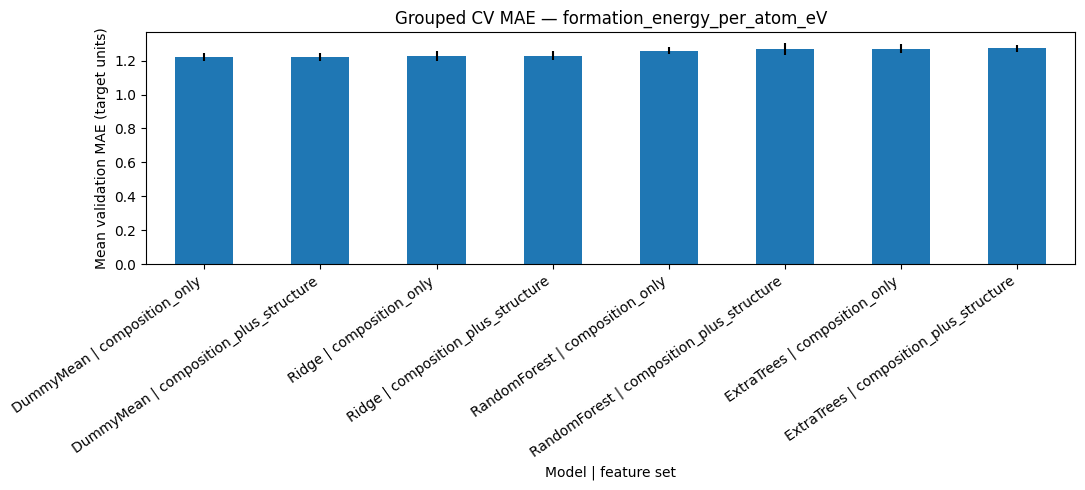

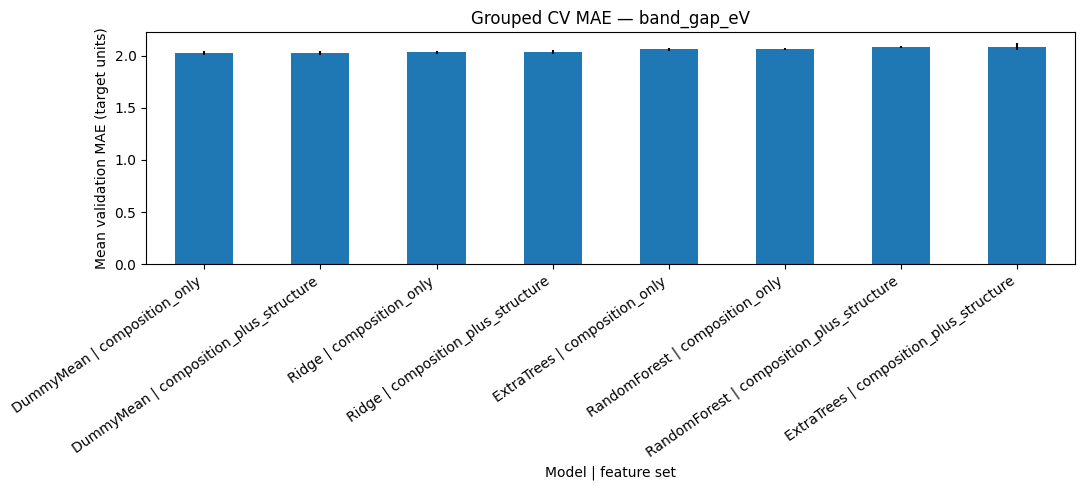

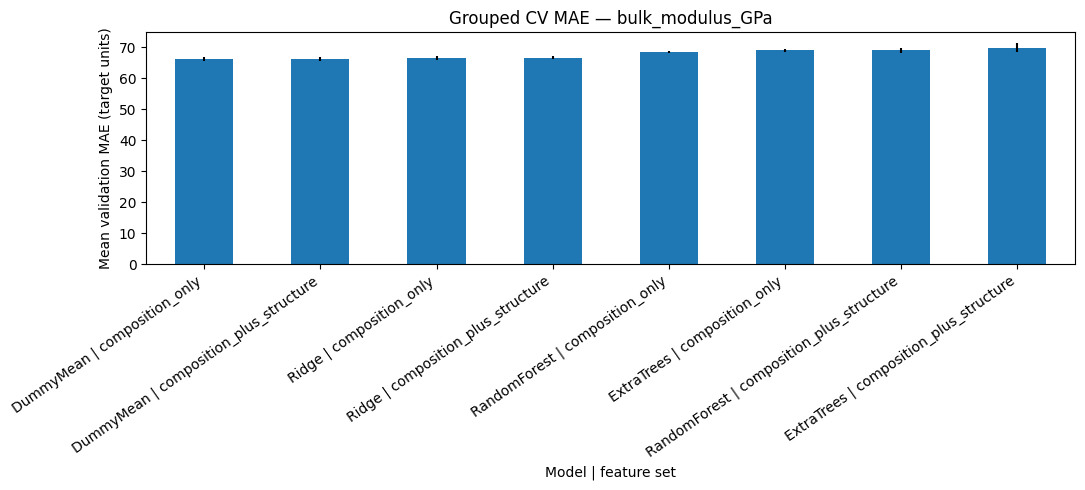

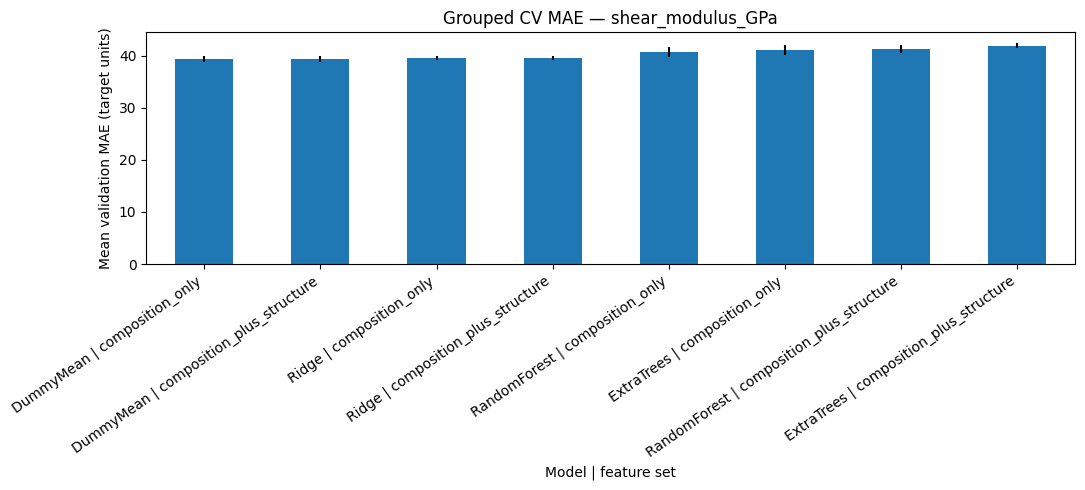

In [5]:
# 4. Grouped cross-validation (training set only)
# Select models using CV MAE; do not use the held-out test set for selection.

N_SPLITS = 3
cv_groups = train["_group_id"].to_numpy()
if pd.Series(cv_groups).nunique() < N_SPLITS:
    raise ValueError(f"Need at least {N_SPLITS} independent training groups.")

cv_splitter = GroupKFold(n_splits=N_SPLITS)
cv_rows = []

for target in TARGETS:
    y_train_all = train[target].astype(float).to_numpy()
    for feature_set_name, feature_cols in feature_sets.items():
        X_train_all = X_all.loc[train.index, feature_cols]
        for model_name, model in models.items():
            fold_rows = []
            for fold_no, (fit_idx, val_idx) in enumerate(
                cv_splitter.split(X_train_all, y_train_all, groups=cv_groups), start=1
            ):
                fit_group_set = set(cv_groups[fit_idx])
                val_group_set = set(cv_groups[val_idx])
                assert fit_group_set.isdisjoint(val_group_set), "Group leakage in CV fold"

                pipe = build_pipeline(model, feature_cols, train)
                pipe.fit(X_train_all.iloc[fit_idx], y_train_all[fit_idx])
                val_pred = pipe.predict(X_train_all.iloc[val_idx])
                y_val = y_train_all[val_idx]
                fold_rows.append({
                    "fold": fold_no,
                    "MAE": mean_absolute_error(y_val, val_pred),
                    "RMSE": mean_squared_error(y_val, val_pred) ** 0.5,
                    "R2": r2_score(y_val, val_pred),
                })

            fold_df = pd.DataFrame(fold_rows)
            cv_rows.append({
                "target": target,
                "feature_set": feature_set_name,
                "model": model_name,
                "CV_MAE_mean": fold_df["MAE"].mean(),
                "CV_MAE_std": fold_df["MAE"].std(ddof=1),
                "CV_RMSE_mean": fold_df["RMSE"].mean(),
                "CV_R2_mean": fold_df["R2"].mean(),
                "folds": N_SPLITS,
            })
        print(f"Grouped CV complete: {target} | {feature_set_name}")

cv_metrics = pd.DataFrame(cv_rows).sort_values(
    ["target", "CV_MAE_mean"]
).reset_index(drop=True)
cv_metrics.to_csv(OUTPUT_DIR / "grouped_cv_comparison.csv", index=False)
print("Grouped CV results (lower MAE is better):")
display(cv_metrics)
print("Saved:", (OUTPUT_DIR / "grouped_cv_comparison.csv").resolve())

# Select one configuration per target using CV MAE only.
selected_cv = (
    cv_metrics.sort_values(["target", "CV_MAE_mean"])
    .groupby("target", as_index=False)
    .first()
)

# Report its untouched held-out test metrics separately.
selected_test = selected_cv.merge(
    metrics,
    on=["target", "feature_set", "model"],
    how="left",
    validate="one_to_one",
    suffixes=("_cv", "_test"),
)
if selected_test["MAE"].isna().any():
    raise ValueError("A CV-selected configuration is missing test metrics.")

# Compare with the mean baseline using the same target and feature set.
dummy_test = metrics.loc[metrics["model"].eq("DummyMean"),
                         ["target", "feature_set", "MAE"]].rename(
    columns={"MAE": "Dummy_test_MAE"}
)
selected_test = selected_test.merge(
    dummy_test, on=["target", "feature_set"], how="left", validate="one_to_one"
)
selected_test["test_MAE_improvement_pct"] = (
    100 * (selected_test["Dummy_test_MAE"] - selected_test["MAE"])
    / selected_test["Dummy_test_MAE"].replace(0, np.nan)
)

print("Models selected using grouped CV, with held-out test results:")
display(selected_test[
    ["target", "feature_set", "model", "CV_MAE_mean", "CV_MAE_std",
     "CV_RMSE_mean", "CV_R2_mean", "MAE", "RMSE", "R2",
     "Dummy_test_MAE", "test_MAE_improvement_pct"]
])
selected_test.to_csv(OUTPUT_DIR / "selected_model_results.csv", index=False)

# Plot CV MAE by candidate configuration.
for target in TARGETS:
    subset = cv_metrics.loc[cv_metrics["target"].eq(target)].copy()
    subset["configuration"] = subset["model"] + " | " + subset["feature_set"]
    subset = subset.sort_values("CV_MAE_mean")
    ax = subset.plot(
        x="configuration", y="CV_MAE_mean", yerr="CV_MAE_std",
        kind="bar", legend=False, figsize=(11, 5),
        title=f"Grouped CV MAE — {target}"
    )
    ax.set_ylabel("Mean validation MAE (target units)")
    ax.set_xlabel("Model | feature set")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    safe_target = re.sub(r"[^A-Za-z0-9_-]+", "_", target)
    plt.savefig(OUTPUT_DIR / f"grouped_cv_mae_{safe_target}.png",
                dpi=140, bbox_inches="tight")
    plt.show()


## 5. Held-out test diagnostics

The candidate configuration is selected using grouped cross-validation on the training set only. The test metrics below are reported once for the selected configuration and are not used to choose it.

In [6]:
# Additional diagnostic: all candidate held-out test scores (descriptive only).
# Do not select models based on this table; selection is based on grouped CV above.
print("Full held-out test comparison (diagnostic only):")
display(metrics.sort_values(["target", "MAE"]))


Full held-out test comparison (diagnostic only):


,target,feature_set,model,n_train,n_test,MAE,RMSE,R2
0,band_gap_eV,composition_only,DummyMean,4454,1046,1.975911,2.453263,-0.000201
1,band_gap_eV,composition_plus_structure,DummyMean,4454,1046,1.975911,2.453263,-0.000201
2,band_gap_eV,composition_only,Ridge,4454,1046,1.988579,2.462928,-0.008097
3,band_gap_eV,composition_plus_structure,Ridge,4454,1046,1.991059,2.463088,-0.008228
4,band_gap_eV,composition_only,RandomForest,4454,1046,2.028638,2.556743,-0.086359
5,band_gap_eV,composition_plus_structure,RandomForest,4454,1046,2.041228,2.566191,-0.094403
6,band_gap_eV,composition_only,ExtraTrees,4454,1046,2.048202,2.586254,-0.111582
7,band_gap_eV,composition_plus_structure,ExtraTrees,4454,1046,2.062296,2.615833,-0.137154
8,bulk_modulus_GPa,composition_only,Ridge,4454,1046,68.232786,84.706915,-0.001044
9,bulk_modulus_GPa,composition_plus_structure,Ridge,4454,1046,68.291557,84.764015,-0.002394


## 6. Export summary and interpretation

The JSON report records split integrity, the CV-selected configuration for each target, and held-out test metrics. Negative test \(R^2\) or failure to beat the mean baseline should be reported honestly; neither is a reason to hide the result.

In [7]:
# Final export and leakage assertions
group_overlap = len(train_groups & test_groups)
chemical_overlap = len(
    set(train["_chemical_system"].dropna()) &
    set(test["_chemical_system"].dropna())
)
material_overlap = len(
    set(train["material_id"].dropna()) &
    set(test["material_id"].dropna())
)
assert group_overlap == 0
assert chemical_overlap == 0
assert material_overlap == 0

summary = {
    "dataset_path": str(data_path.resolve()),
    "rows_total": int(len(df)),
    "rows_formula_parsed": int(valid_formula.sum()),
    "rows_modelled": int(len(work)),
    "n_elements": int(len(all_elements)),
    "train_rows": int(len(train)),
    "test_rows": int(len(test)),
    "connected_groups": int(work["_group_id"].nunique()),
    "group_overlap": group_overlap,
    "chemical_system_overlap": chemical_overlap,
    "material_id_overlap": material_overlap,
    "cv_folds": int(N_SPLITS),
    "model_selection_metric": "mean grouped-CV MAE on training set",
    "targets": TARGETS,
    "feature_sets": list(feature_sets.keys()),
    "selected_models": selected_test[
        ["target", "feature_set", "model", "CV_MAE_mean", "CV_MAE_std",
         "MAE", "RMSE", "R2", "Dummy_test_MAE",
         "test_MAE_improvement_pct"]
    ].to_dict(orient="records"),
    "limitations": [
        "Experimental sample data; metrics do not establish scientific validity.",
        "Flat formula parser does not support parentheses, hydrates, charges, or fractional syntax beyond decimal stoichiometry.",
        "Grouped validation estimates performance on held-out connected chemical-system/material-ID groups.",
        "No crystal coordinates or atomic structures are supplied, so crystal-graph models cannot be trained from this CSV alone.",
        "Do not repeatedly tune against the held-out test set.",
    ],
}
summary_path = OUTPUT_DIR / "run_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("Outputs folder:", OUTPUT_DIR.resolve())


{
  "dataset_path": "C:\\Users\\Amey Ravindra Pandit\\Downloads\\MAT Risk\\Data\\raw\\DS1_material_properties_5500.csv",
  "rows_total": 5500,
  "rows_formula_parsed": 5500,
  "rows_modelled": 5500,
  "n_elements": 62,
  "train_rows": 4454,
  "test_rows": 1046,
  "connected_groups": 3730,
  "group_overlap": 0,
  "chemical_system_overlap": 0,
  "material_id_overlap": 0,
  "cv_folds": 3,
  "model_selection_metric": "mean grouped-CV MAE on training set",
  "targets": [
    "formation_energy_per_atom_eV",
    "band_gap_eV",
    "bulk_modulus_GPa",
    "shear_modulus_GPa"
  ],
  "feature_sets": [
    "composition_only",
    "composition_plus_structure"
  ],
  "selected_models": [
    {
      "target": "band_gap_eV",
      "feature_set": "composition_only",
      "model": "DummyMean",
      "CV_MAE_mean": 2.0295302680379925,
      "CV_MAE_std": 0.01706898903029261,
      "MAE": 1.9759106983560872,
      "RMSE": 2.4532628633269025,
      "R2": -0.0002011507907251353,
      "Dummy_test_MAE": 1